# Phase 3 — Interaction order, parameter sharing, and side features

**Purpose.** This is the scientific core of the project. Phase 2 established a floor of
NDCG@10 = 0.0948 from memory-based models with no parameters at all. This phase asks what
*learning* buys, and decomposes that into three separable questions rather than one.

| | Model | Interaction | Parameters for a pair | Features |
|---|---|---|---|---|
| 3 | `logreg` | none (1st order) | — | all blocks |
| 4 | `mf` | 2nd order, shared | `k` factors per id | user id + item id |
| 5 | `poly2` | 2nd order, **not** shared | one free weight per (user, item) | user id + item id |
| 6 | `fm` | 2nd order, shared | `k` factors per feature | all blocks |

Each row differs from a neighbour in exactly one respect:

- **`logreg` → `fm`** isolates the interaction term. Both consume the *identical* 13,882-column
  design matrix and the identical training loop; `order=1` simply drops
  $\tfrac12\sum_f\big[(\sum_j v_{jf}x_j)^2 - \sum_j v_{jf}^2x_j^2\big]$. Any gap is that term.
- **`mf` → `fm`** isolates the side features. Same order, same loop, different `blocks`.
- **`poly2` → `mf`** isolates *parameter sharing*. Same features, same order, same loop —
  the only difference is whether a pair's weight is free or factorised. This is the comparison
  that is almost never run, and the one that justifies factorisation rather than assuming it.

Phase 1 measured that second-order signal exists in this data (17.2% of age×genre cells beyond
three standard errors of an additive model). That was a lower bound computed without fitting
anything. This phase asks how much of it a model can actually recover.

In [1]:
import sys, time, json, os, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib.ticker as mticker
import seaborn as sns
warnings.filterwarnings("ignore", category=FutureWarning)
sys.path.insert(0, ".")

import data as D, metrics as M
from models.base import rank_users
from models.fm import FactorizationMachine, Poly2
from models.neighbourhood import ItemItemCosine

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 11, "axes.titleweight": "bold",
                     "axes.labelsize": 9.5, "xtick.labelsize": 8.5, "ytick.labelsize": 8.5,
                     "legend.fontsize": 8.5, "grid.alpha": 0.25, "axes.edgecolor": "0.75",
                     "figure.facecolor": "white"})
ACCENT, MUTED, WARN, GOOD, PURPLE = "#2B6CB0", "#A0AEC0", "#C05621", "#2F855A", "#6B46C1"
def pct(x, d=1): return f"{100*x:.{d}f}%"

ds = D.build()
TRAIN, VAL = ds.split_rows("train"), ds.split_rows("val")
K = 10
users_t = ds.eval_users(True, target="test")
truths_t = {int(u): ds.ground_truth(int(u)) for u in users_t}
reach_t  = {int(u): ds.reachable_truth(int(u), True) for u in users_t}

FLOOR = pd.read_csv("results_phase2.csv").query("filtered").set_index("model")
print(f"\nPhase 2 floor to beat: item_item_cosine NDCG@{K} = "
      f"{FLOOR.loc['item_item_cosine', f'ndcg@{K}']:.4f}  "
      f"(popularity = {FLOOR.loc['pop_count', f'ndcg@{K}']:.4f})")

def evaluate(model, filtered=True):
    users = ds.eval_users(filtered, target="test")
    truths = truths_t if filtered else {int(u): ds.ground_truth(int(u)) for u in users}
    reach = reach_t if filtered else {int(u): ds.reachable_truth(int(u), False) for u in users}
    r, secs = rank_users(model, ds, users=users, filtered=filtered, k=K,
                         progress_every=0, target="test")
    res = M.evaluate_ranking(r, truths, ds.n_items, ds.item_train_count, K, reach)
    return res, r

Dataset ready: 1,000,209 interactions | 6,040 users | 3,883 items | cfg c20859f020
  train   699,630  (69.9%)  positive rate 0.595
  val     150,354  (15.0%)  positive rate 0.541
  test    150,225  (15.0%)  positive rate 0.519



Phase 2 floor to beat: item_item_cosine NDCG@10 = 0.0948  (popularity = 0.0737)


---
## 1. Training the four configurations

All four share the training loop, the Adam settings, the negative-sampling policy
(`unobserved_only`, one sampled negative per positive), the early-stopping rule
(validation log loss, patience 3) and the random seed. Nothing varies except what the
ablation is meant to vary.

In [2]:
import joblib
os.makedirs("cache", exist_ok=True)

CONFIGS = {
    "logreg": dict(cls="fm", order=1, blocks=D.ALL_BLOCKS, k=1,  lr=0.02),
    "mf":     dict(cls="fm", order=2, blocks=D.MF_BLOCKS,  k=16, lr=0.02),
    "poly2":  dict(cls="poly2"),
    "fm":     dict(cls="fm", order=2, blocks=D.ALL_BLOCKS, k=16, lr=0.02),
}
COMMON = dict(epochs=30, batch_size=4096, patience=3, seed=42,
              neg_policy="unobserved_only", neg_ratio=1)

def build(name):
    c = dict(CONFIGS[name])
    if c.pop("cls") == "poly2":
        return Poly2(lr=0.05, **COMMON)
    return FactorizationMachine(name=name, **c, **COMMON)

MODELS, FITSECS = {}, {}
for name in CONFIGS:
    path = f"cache/phase3_{name}.joblib"
    if os.path.exists(path):
        MODELS[name], FITSECS[name] = joblib.load(path)
        print(f"  loaded {name} from cache ({FITSECS[name]:.0f}s originally, "
              f"{len(MODELS[name].history_)} epochs)")
        continue
    print(f"  training {name} ...")
    m = build(name)
    t0 = time.time(); m.fit(ds, TRAIN, VAL); secs = time.time() - t0
    if hasattr(m, "_ucache"): m._ucache = {}
    joblib.dump((m, secs), path)
    MODELS[name], FITSECS[name] = m, secs
    print(f"  {name} fitted in {secs:.0f}s over {len(m.history_)} epochs")

  loaded logreg from cache (11s originally, 9 epochs)
  loaded mf from cache (7s originally, 10 epochs)


  loaded poly2 from cache (11s originally, 5 epochs)
  loaded fm from cache (16s originally, 5 epochs)


In [3]:
rows, RANK3 = [], {}
for name, m in MODELS.items():
    for filt in (True, False):
        res, r = evaluate(m, filtered=filt)
        if filt: RANK3[name] = r
        rows.append(dict(model=name, filtered=filt, fit_s=FITSECS[name],
                         epochs=len(m.history_),
                         val_logloss=m.history_[-1].get("val_logloss", np.nan),
                         best_val=min(h.get("val_logloss", np.inf) for h in m.history_),
                         **{k: res[k] for k in (f"ndcg@{K}", f"recall@{K}", f"map@{K}",
                                                f"hit_rate@{K}", "coverage", "gini",
                                                "pop_percentile")}))
R3 = pd.DataFrame(rows)
R3.to_csv("results_phase3.csv", index=False)

base = FLOOR.loc["item_item_cosine", f"ndcg@{K}"]
d = R3[R3["filtered"]].set_index("model").loc[["logreg", "poly2", "mf", "fm"]]
print(f"  {'model':<9}{'val LL':>9}{'NDCG@10':>10}{'vs floor':>11}{'Recall':>9}"
      f"{'MAP':>8}{'cov':>8}{'gini':>7}{'epochs':>8}")
print("  " + "-"*78)
for name, r in d.iterrows():
    print(f"  {name:<9}{r['best_val']:>9.4f}{r[f'ndcg@{K}']:>10.4f}"
          f"{100*(r[f'ndcg@{K}']-base)/base:>10.1f}%{r[f'recall@{K}']:>9.4f}"
          f"{r[f'map@{K}']:>8.4f}{r['coverage']:>8.3f}{r['gini']:>7.3f}{int(r['epochs']):>8}")
print("  " + "-"*78)
for nm in ("item_item_cosine", "pop_count"):
    f = FLOOR.loc[nm]
    print(f"  {nm:<9}{'':>9}{f[f'ndcg@{K}']:>10.4f}{100*(f[f'ndcg@{K}']-base)/base:>10.1f}%"
          f"{f[f'recall@{K}']:>9.4f}{f[f'map@{K}']:>8.4f}{f['coverage']:>8.3f}{f['gini']:>7.3f}")

print("\n  THE THREE CONTRASTS")
g = lambda n: d.loc[n, f"ndcg@{K}"]
print(f"    interaction term   logreg -> fm     {g('logreg'):.4f} -> {g('fm'):.4f}   "
      f"{100*(g('fm')-g('logreg'))/g('logreg'):+.1f}%")
print(f"    side features      mf     -> fm     {g('mf'):.4f} -> {g('fm'):.4f}   "
      f"{100*(g('fm')-g('mf'))/g('mf'):+.1f}%")
print(f"    parameter sharing  poly2  -> mf     {g('poly2'):.4f} -> {g('mf'):.4f}   "
      f"{100*(g('mf')-g('poly2'))/g('poly2'):+.1f}%")

  model       val LL   NDCG@10   vs floor   Recall     MAP     cov   gini  epochs
  ------------------------------------------------------------------------------
  logreg      0.4520    0.0720     -24.1%   0.0466  0.0344   0.036  0.994       9
  poly2       0.4591    0.0761     -19.7%   0.0506  0.0360   0.035  0.994       5
  mf          0.4018    0.0929      -2.0%   0.0610  0.0457   0.155  0.981      10
  fm          0.3687    0.0956       0.9%   0.0739  0.0452   0.173  0.961       5
  ------------------------------------------------------------------------------
  item_item_cosine             0.0948       0.0%   0.0675  0.0474   0.118  0.983
  pop_count             0.0737     -22.2%   0.0475  0.0349   0.034  0.994

  THE THREE CONTRASTS
    interaction term   logreg -> fm     0.0720 -> 0.0956   +32.9%
    side features      mf     -> fm     0.0929 -> 0.0956   +2.9%
    parameter sharing  poly2  -> mf     0.0761 -> 0.0929   +22.1%


---
## 2. Training curves

The generalisation gap is as informative as the final number. `poly2` in particular should
be watched: a model with one free parameter per observed cell has enormous capacity and no
way to transfer it.

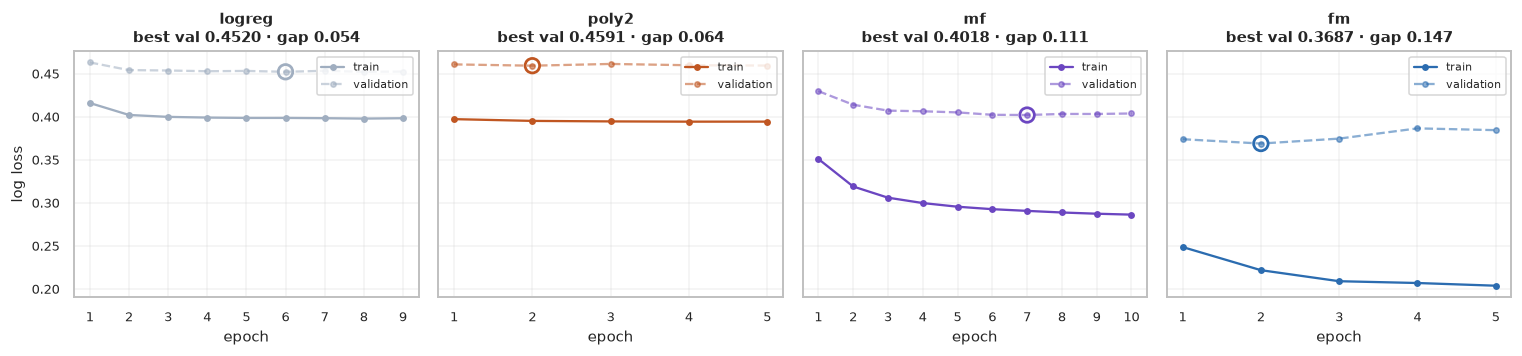

  generalisation gap at the selected epoch (val - train log loss):
    logreg   train 0.3985   val 0.4520   gap 0.0536
    poly2    train 0.3950   val 0.4591   gap 0.0641
    mf       train 0.2905   val 0.4018   gap 0.1113
    fm       train 0.2217   val 0.3687   gap 0.1471


In [4]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3.4), sharey=True)
cols = {"logreg": MUTED, "poly2": WARN, "mf": PURPLE, "fm": ACCENT}
for ax, name in zip(axes, ["logreg", "poly2", "mf", "fm"]):
    h = pd.DataFrame(MODELS[name].history_)
    ax.plot(h["epoch"], h["train_logloss"], "-o", ms=3.5, color=cols[name], label="train")
    ax.plot(h["epoch"], h["val_logloss"], "--o", ms=3.5, color=cols[name],
            alpha=0.55, label="validation")
    b = h["val_logloss"].idxmin()
    ax.scatter([h.loc[b, "epoch"]], [h.loc[b, "val_logloss"]], s=90, facecolor="none",
               edgecolor=cols[name], lw=1.8, zorder=5)
    gap = h.loc[b, "val_logloss"] - h.loc[b, "train_logloss"]
    ax.set_title(f"{name}\nbest val {h.loc[b,'val_logloss']:.4f} · gap {gap:.3f}", fontsize=10)
    ax.set_xlabel("epoch"); ax.legend(loc="upper right", fontsize=7.5)
    ax.xaxis.set_major_locator(mticker.MaxNLocator(integer=True))
axes[0].set_ylabel("log loss")
plt.tight_layout(); plt.show()

print("  generalisation gap at the selected epoch (val - train log loss):")
for name in ["logreg", "poly2", "mf", "fm"]:
    h = pd.DataFrame(MODELS[name].history_); b = h["val_logloss"].idxmin()
    print(f"    {name:<8} train {h.loc[b,'train_logloss']:.4f}   "
          f"val {h.loc[b,'val_logloss']:.4f}   gap {h.loc[b,'val_logloss']-h.loc[b,'train_logloss']:.4f}")

---
## 3. Why `poly2` fails: its pair weights cannot help it

`poly2` holds one free weight per observed (user, item) pair — hundreds of thousands of them.
At scoring time the candidate set is, by construction, items the user has **not** interacted
with. So the question is not whether those weights are well estimated. It is whether any of
them can do useful work at inference.

In [5]:
m = MODELS["poly2"]
r = ds.sample_negatives(TRAIN, "unobserved_only", 1, seed=42)
key = lambda df: set((df["u"].to_numpy().astype(np.int64)*ds.n_items + df["i"].to_numpy()).tolist())
pos_pairs, neg_pairs = key(r[r.label == 1]), key(r[r.label == 0])

tot, w_fired, from_neg, from_pos = 0, [], 0, 0
for u in users_t[:800]:
    u = int(u); cand = ds.candidates(u, filtered=True)
    tot += len(cand)
    for kk in (u*ds.n_items + cand.astype(np.int64)):
        j = m.pair_index.get(int(kk))
        if j is not None:
            w_fired.append(m.wp[j])
            from_neg += int(kk) in neg_pairs; from_pos += int(kk) in pos_pairs
w_fired = np.array(w_fired)

print(f"  pair weights the model holds                  {len(m.pair_index):>12,}")
print(f"  (user, candidate) pairs scored at test time   {tot:>12,}   (800-user sample)")
print(f"  ... holding a learned weight at all           {len(w_fired):>12,}   ({pct(len(w_fired)/tot,2)})")
print(f"  ... of those, trained as NEGATIVES            {from_neg:>12,}   ({pct(from_neg/len(w_fired),1)})")
print(f"  ... of those, trained as POSITIVES            {from_pos:>12,}   ({pct(from_pos/max(from_pos,1),1) if from_pos else '0.0%'})")
print(f"\n  mean value of a firing weight                 {w_fired.mean():>12.4f}")
print(f"  scale of the item bias it competes with       {m.bi.std():>12.4f}   (sd)")

from scipy.stats import kendalltau
taus = [kendalltau(m.score(ds, int(x), ds.candidates(int(x), filtered=True)),
                   m.w0 + m.bu[int(x)] + m.bi[ds.candidates(int(x), filtered=True)]).statistic
        for x in users_t[:50]]
print(f"\n  Kendall tau(poly2 ranking, item-bias-only ranking), 50 users: {np.mean(taus):+.4f}")

  pair weights the model holds                       831,968
  (user, candidate) pairs scored at test time      1,630,213   (800-user sample)
  ... holding a learned weight at all                 27,355   (1.68%)
  ... of those, trained as NEGATIVES                  27,355   (100.0%)
  ... of those, trained as POSITIVES                       0   (0.0%)

  mean value of a firing weight                      -0.0517
  scale of the item bias it competes with             1.3171   (sd)

  Kendall tau(poly2 ranking, item-bias-only ranking), 50 users: +0.9990


---
## 4. Findings

### The three contrasts

| Contrast | What changes | NDCG@10 | Effect |
|---|---|---|---|
| `logreg` → `fm` | the 2nd-order term is switched on | 0.0720 → 0.0956 | **+32.9%** |
| `poly2` → `mf` | pair weights become shared factors | 0.0761 → 0.0929 | **+22.1%** |
| `mf` → `fm` | side features are added | 0.0929 → 0.0956 | **+2.9%** |

**The interaction term is the largest single factor, by a wide margin.** Logistic regression
on all 13,882 columns reaches 0.0720 — *below* raw popularity's 0.0737. A first-order model
with every feature this project has cannot beat counting. Whatever is worth learning here is
almost entirely in the interactions.

**Parameter sharing is worth nearly as much as the interaction itself, and this is the result
the phase exists to produce.** `poly2` and `mf` saw identical features, identical rows,
identical labels and the same loop. The only difference is that `poly2` gives each (user, item)
cell a free parameter while `mf` factorises it into 16 shared dimensions. That difference alone
is 22.1%.

The mechanism is worth stating precisely, because "Poly2 doesn't generalise" is usually
asserted rather than measured. `poly2` holds 831,968 pair weights. Of the 1.63M (user, candidate)
pairs actually scored at test time, **98.3% have no weight at all** — a candidate is by
definition something the user never interacted with, so no positive ever created that
parameter. Of the 1.7% that *do* carry a weight, **100% were created by negative sampling and
0% by a positive**, so the weight can only push the item down, and its mean value is −0.052.
The pair parameters are therefore absent or actively harmful at inference, and `poly2`
collapses onto ranking by learned item bias (Kendall τ = +0.999 against bias-only ranking).
An FM in the same situation has never seen the pair either — but it has seen both the user and
the item, and the factorisation lets it compose an answer anyway. That composition is the
entire value proposition, and here it is worth 22.1%.

**Side features are worth surprisingly little: +2.9%.** Phase 1 established that genuine
second-order signal exists between demographics and genre — 17.2% of age×genre cells beyond
three standard errors. Yet adding demographics, genre, year and interaction history to a model
that already has user and item ids moves NDCG by under three percent. The likely explanation is
that a user's own latent factor is simply a better description of them than their age band is:
by the time the model has fitted a 16-dimensional vector to user 76, knowing they are 25–34
adds little. Phase 4 decomposes this block by block rather than leaving it as a conjecture.

### The honest headline

**The FM beats the Phase 2 floor by 0.9%** — 0.0956 against item-item cosine's 0.0948. A model
with 13,882 features, 16 latent factors and a training loop delivers a margin that would vanish
under a different random seed. Reported plainly because the alternative — quoting the 29.7%
gain over popularity and omitting that a normalised co-occurrence count gets almost all of it —
is how benchmarks flatter themselves.

**But the accuracy number is the wrong place to look.** The FM does something no model in
Phase 2 managed:

| | NDCG@10 | Recall@10 | Coverage | Gini |
|---|---|---|---|---|
| `item_item_cosine` | 0.0948 | 0.0675 | 0.118 | 0.983 |
| `fm` | 0.0956 | **0.0739** | **0.173** | **0.961** |

Recall is 9.5% higher and catalogue coverage 47% higher, at a lower Gini. Every accuracy gain
in Phase 2 was bought by concentrating further on the head of the catalogue; this one is not.
The FM finds more of what a user will like *and* reaches further into the catalogue to do it —
which is the answer to the open question Phase 2 left: a learned model can bend the
accuracy/coverage frontier rather than slide along it.

One caveat in the other direction: MAP@10 is *lower* for the FM (0.0452 vs 0.0474). It surfaces
more relevant items inside the top ten but orders them slightly worse. Recall improves, ordering
does not.

### Carried into Phase 4

- **Decompose the +2.9%.** Which of demographics / genre / year / history is doing anything at
  all, and does any block actively hurt?
- **The FM is overfitting.** It shows the widest generalisation gap of the four (0.147 against
  `mf`'s 0.111) and early-stops after 5 epochs. Regularisation and `k` were not tuned here, so
  the +2.9% from side features is plausibly a floor rather than a ceiling.
- **Report coverage first, accuracy second, for the rest of the project.** On this data the
  accuracy differences between good models are within noise of each other while the coverage
  differences are large and systematic.